# BERT

Ở bài 6.1, câu “bài giảng không hay” bị đoán là khen, vì baseline chỉ đếm từ và không thấy “không” đi với “hay”. Để hiểu câu, vector của mỗi từ phải phụ thuộc vào các từ xung quanh. BERT là model Transformer đọc cả câu theo hai chiều và cho mỗi token một vector theo ngữ cảnh. Bài này học cách BERT được huấn luyện, và cách thêm một lớp nhỏ lên trên để dùng BERT phân loại câu hoặc gán nhãn từng token.

> **Mục tiêu**
>
> - Hiểu cách BERT được huấn luyện (masked language modeling).
> - Theo dõi shape từ token tới đầu ra cho cả câu và cho từng token.
> - Huấn luyện một encoder nhỏ từ đầu.
> - Gán nhãn từng token (NER) khi một từ bị tách thành nhiều subword.

## Token có ngữ cảnh, không chỉ một hàng trong bảng

Embedding đầu vào là phép tra bảng: token ID $t_i$ lấy vector $E[t_i]$. Sau encoder, hidden state $\mathbf{h}_i$ phụ thuộc các token được phép nhìn trong câu. “đường” trong “đường đi” và “đường ngọt” bắt đầu ở cùng một hàng embedding nhưng nhận hidden states khác nhau. Embedding tĩnh như word2vec (bài 3.8) chỉ có một vector cho “bank”, dù nghĩa là bờ sông hay ngân hàng; hidden state của encoder thì tách được hai nghĩa. Positional embedding bổ sung vị trí, vì self-attention không tự biết thứ tự từ chỉ từ một tập vector.

**Hỏi nhanh.** Để phân biệt “đường” là lối đi với “đường” là vị ngọt, một bạn lấy `token_embedding.weight[id("đường")]` của checkpoint BERT làm vector của từ trong từng câu. Cách này cho ra gì?

- A. Hai vector khác nhau, vì BERT là model hai chiều
- B. Hai vector giống hệt, vì đó chỉ là một hàng của bảng tra
- C. Hai vector khác nhau, vì đã cộng position embedding
- D. Code báo lỗi, vì embedding chỉ đọc được bên trong `forward`

<details><summary>Đáp án</summary>

B. Hai vector giống hệt, vì đó chỉ là một hàng của bảng tra

Bảng embedding chỉ phụ thuộc token ID, nên hai câu tra ra đúng một hàng. Tính hai chiều nằm ở các lớp attention phía sau. Vector theo ngữ cảnh là hidden state tại vị trí của “đường” sau khi qua encoder. Position embedding được cộng trong `forward`, không nằm trong hàng bảng tra, và nó chỉ phụ thuộc vị trí chứ không phụ thuộc nghĩa. Đọc một tham số bằng chỉ số thì không báo lỗi gì.

</details>

BERT là tên một họ model và một phương pháp pretraining cụ thể, không phải tên của mọi encoder. BERT gốc dùng WordPiece, token embedding, position embedding và token-type embedding để đánh dấu đoạn A/B. Một số biến thể bỏ hoặc đổi token-type embedding, tokenizer hoặc mục tiêu học. Vì vậy cần đọc config và model card của đúng checkpoint; PhoBERT, RoBERTa hay DistilBERT không thừa hưởng mọi đặc điểm của BERT gốc.

Một attention head tính điểm giữa query và key. Với ma trận $Q,K,V$ rút từ hidden states, ta dùng

$$A=\operatorname{softmax}\left(\frac{QK^{\top}}{\sqrt{d_k}}+M\right),\qquad H'=AV.$$

Softmax theo chiều key làm mỗi hàng thành phân phối trọng số. $M$ đặt $-\infty$ ở liên kết bị cấm để sau softmax trọng số bằng 0. Encoder BERT không dùng tam giác causal cho các token thật: khi đọc một câu hoàn chỉnh để phân loại, nó được nhìn hai phía. Đó cũng là khác biệt chính giữa BERT và GPT: BERT là encoder đọc hai phía để hiểu câu, GPT là decoder chỉ nhìn bên trái để sinh tiếp. Nhưng vẫn cần mask padding. Causal mask dành cho dự đoán tiếp token ở bài 6.4; dùng nhầm hai loại mask có thể làm đổi nhiệm vụ hoặc lộ đáp án.

**Hỏi nhanh.** Câu có 3 token thật, được pad thêm 2 PAD thành độ dài 5. Ở hàng attention của token thật thứ hai, encoder BERT và decoder causal lần lượt cho phép bao nhiêu key?

- A. Encoder 3, causal 2
- B. Encoder 5, causal 2
- C. Encoder 3, causal 3
- D. Encoder 2, causal 3

<details><summary>Đáp án</summary>

A. Encoder 3, causal 2

Encoder nhìn mọi token thật ở cả hai phía, còn padding mask chặn 2 cột PAD, nên còn 3 key. Causal mask chỉ cho key ở các vị trí trước và chính nó, tức token thứ nhất và thứ hai, nên có 2 key. Con số 5 là quên padding mask. “Causal 3” là decoder bị quên causal mask, nên đọc cả token thứ ba.

</details>



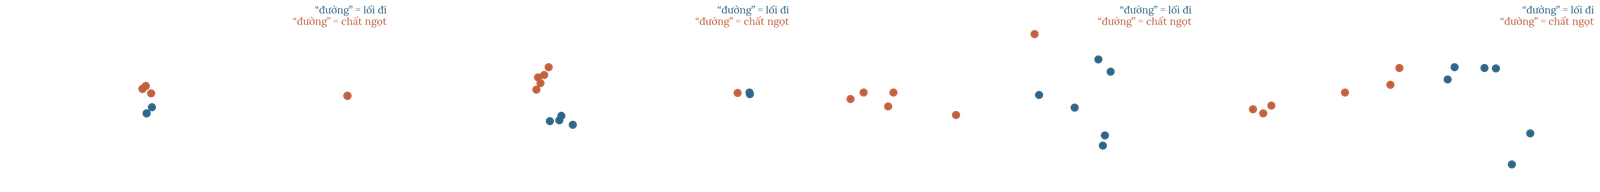

## BERT học trước bằng cách che một phần câu

Masked language modeling (MLM) chọn một số vị trí, làm biến đổi token đầu vào ở đó, rồi yêu cầu đoán token gốc. Ví dụ “An [MASK] sách” có thể cần “đọc”. Loss chỉ tính trên các vị trí được chọn; các token còn lại chỉ đóng vai ngữ cảnh. BERT gốc chọn 15% vị trí; trong số đó 80% thay bằng `[MASK]`, 10% thay bằng token ngẫu nhiên, 10% giữ nguyên. Lý do nằm ở fine-tuning: `[MASK]` không bao giờ xuất hiện trong câu thật, nên nếu mọi vị trí được chấm đều mang `[MASK]`, model chỉ cần biểu diễn tốt ở những chỗ có ký hiệu ấy. Khi một token thật cũng có thể là vị trí bị chấm, model phải giữ biểu diễn tốt cho mọi token. [Bài báo BERT](https://aclanthology.org/N19-1423/).

Nếu tập vị trí được chọn là $S$, loss MLM là

$$\mathcal{L}_{\mathrm{MLM}}=-\frac{1}{|S|}\sum_{i\in S}\log p_\theta(t_i\mid\widetilde{t}_1,\ldots,\widetilde{t}_L).$$

Dấu ngã nhắc rằng chuỗi đầu vào đã được làm biến đổi. Nhãn $t_i$ vẫn là token gốc. MLM học từ corpus không có nhãn phân loại, còn fine-tuning học từ các câu có nhãn nhiệm vụ. Pretraining không tự cho biết nhận xét nào tích cực; head phân loại và nhiều khi cả encoder phải được điều chỉnh.

**Hỏi nhanh.** Một vị trí được chọn cho MLM chứa token gốc “đọc”, và ở lượt này đầu vào tại đó được thay bằng `[MASK]`. Nhãn của vị trí ấy là gì?

- A. ID của `[MASK]`, vì đó là token model nhìn thấy
- B. `-100`, vì vị trí đã bị che thì bỏ khỏi loss
- C. Nhãn cảm xúc của cả câu chứa vị trí ấy
- D. ID của “đọc”, token gốc trước khi bị che

<details><summary>Đáp án</summary>

D. ID của “đọc”, token gốc trước khi bị che

MLM khôi phục token gốc. Lấy ID của `[MASK]` làm nhãn là biến bài toán thành chép lại đầu vào. `-100` dành cho những vị trí **không** được chọn, ngược hẳn vai trò ở đây. Nhãn cảm xúc thuộc về bước fine-tune, không có trong corpus pretraining.

</details>



**Hỏi nhanh.** Một câu có 40 token thật và 24 PAD. MLM chọn 6 vị trí, và tổng $-\log p$ của token gốc trên 6 vị trí ấy là 9.0. $\mathcal{L}_{\mathrm{MLM}}$ của câu bằng bao nhiêu?

- A. 0.1406
- B. 0.225
- C. 1.5
- D. 9.0

<details><summary>Đáp án</summary>

C. 1.5

Mẫu số là $|S| = 6$, nên loss bằng $9.0/6 = 1.5$. Chia cho 64, tính cả PAD, ra 0.1406. Chia cho 40 token thật ra 0.225. Cả hai cách làm loss nhỏ đi theo độ dài câu, dù model đoán dở như nhau. 9.0 là tổng, chưa lấy trung bình.

</details>

## Hai nhiệm vụ, hai vị trí đặt head

Encoder trả $H$ có shape `(B, L, d)`. Sequence classification cần một dự đoán cho mỗi câu; có thể lấy hidden state của `[CLS]` hoặc pooling theo recipe, rồi đưa qua linear head thành `(B, C)`, với $C$ lớp. Token classification cần một dự đoán cho mỗi vị trí; linear head trên từng $\mathbf{h}_i$ cho `(B, L, C)`. NER thường dùng BIO: `B-LOC` bắt đầu địa danh, `I-LOC` tiếp tục địa danh, `O` ở ngoài thực thể: “Nguyễn Văn An đến Huế” là `B-PER I-PER I-PER O B-LOC`. Gán từ loại (danh từ, động từ...) cho từng từ cũng là token classification; thêm dấu cho văn bản không dấu, “toi di hoc” thành “tôi đi học”, thường được làm như vậy, mỗi âm tiết một nhãn.

Cặp câu được ghép thành `[CLS] A [SEP] B [SEP]`, với `token_type_ids` bằng 0 cho phần A, kể cả `[CLS]` và `[SEP]` đầu, và bằng 1 cho phần B. Head phân loại 3 lớp trên bert-base (ẩn 768) có $768 \cdot 3 + 3 = 2307$ tham số. `attention_mask` của Hugging Face dùng 1 cho token giữ lại, ngược với `key_padding_mask` của `nn.MultiheadAttention` (True là bỏ), nên phải đảo trước khi chuyển.



| Đại lượng | Shape | Kiểu hoặc ý nghĩa |
|---|---|---|
| `input_ids` | `(B, L)` | số nguyên, dùng tra bảng |
| `attention_mask` kiểu HF | `(B, L)` | 1 giữ, 0 padding |
| `last_hidden_state` | `(B, L, d)` | vector ngữ cảnh |
| logits phân loại câu | `(B, C)` | điểm trước softmax |
| logits gán nhãn token | `(B, L, C)` | một hàng điểm mỗi vị trí |

Head pretrained cho MLM không thể dùng nguyên như head NER vì số lớp và ý nghĩa đầu ra khác nhau. Một head nhiệm vụ mới thường khởi tạo ngẫu nhiên; trọng số pretrained chỉ nằm ở backbone. Vì vậy dự đoán in ra ngay sau khi gắn head chưa mang thông tin gì về nhiệm vụ; head phải được học trên dữ liệu có nhãn.

Extractive question answering (chọn đoạn trả lời nằm sẵn trong văn bản, như bộ SQuAD) cũng dùng head token. Câu hỏi và đoạn văn được ghép thành một chuỗi `[CLS] câu hỏi [SEP] đoạn văn [SEP]`; mỗi vị trí cho hai logits, một cho “bắt đầu đáp án”, một cho “kết thúc đáp án”, nên logits có shape `(B, L, 2)`. Softmax lấy theo chiều vị trí $L$, không theo chiều 2: hai số ở một vị trí không phải hai lớp cạnh tranh nhau, mà là điểm của vị trí ấy trong hai cuộc chọn riêng.

**Hỏi nhanh.** Head trích đoạn trả về logits `(1, 384, 2)`. Argmax của logits “bắt đầu” rơi vào vị trí 57, còn argmax của logits “kết thúc” rơi vào vị trí 41. Đọc đáp án thế nào?

- A. Đảo hai đầu, lấy đoạn từ vị trí 41 đến 57
- B. Chọn cặp $i \le j$ có tổng hai điểm lớn nhất
- C. Trả về rỗng, vì hai argmax không tạo được đoạn hợp lệ
- D. Chỉ lấy token 57, vì điểm bắt đầu chắc hơn

<details><summary>Đáp án</summary>

B. Chọn cặp $i \le j$ có tổng hai điểm lớn nhất

Hai argmax tách rời không bảo đảm thứ tự. BERT chấm mỗi đoạn ứng viên $(i, j)$ bằng tổng điểm “bắt đầu” tại $i$ và điểm “kết thúc” tại $j$, rồi chọn đoạn tốt nhất với $j \ge i$, thường kèm giới hạn độ dài và chỉ xét vị trí trong đoạn văn. Đảo hai đầu tạo ra một đoạn mà model không hề chấm cao. Trả về rỗng chỉ hợp lý khi đề cho phép “không có đáp án” và điểm của `[CLS]` cao hơn mọi đoạn. Một token lẻ bỏ mất phần còn lại của đáp án.

</details>

## Một encoder nhỏ học từ đầu trên CPU

Ta dựng một encoder một lớp, hidden size 16 và hai attention heads, rồi dạy nó phân loại mười câu tự soạn. Kiến trúc giống một lớp của BERT: token embedding cộng position embedding, self-attention hai chiều có padding mask, head đọc CLS. Khác biệt là model học thẳng nhiệm vụ phân loại từ khởi tạo ngẫu nhiên, bỏ qua giai đoạn MLM; mọi tensor đủ nhỏ để in ra và cả bài chạy trên CPU trong vài giây. Câu được tách bằng `split()`; `ví_dụ` viết liền để thành một token. Nhãn theo đúng khó khăn ở đầu bài: “hay” và “không tệ” là 1, “tệ” và “không hay” là 0.

In [ ]:
import torch
from torch import nn

torch.manual_seed(63)
torch.set_num_threads(1)
train_texts = [
    "bài hay", "bài không tệ", "ví_dụ hay", "ví_dụ không tệ", "giảng hay",
    "bài tệ", "bài không hay", "ví_dụ tệ", "ví_dụ không hay", "giảng không tệ",
]
train_labels = torch.tensor([1, 1, 1, 1, 1, 0, 0, 0, 0, 1])
valid_texts = ["giảng tệ", "giảng không hay"]
valid_labels = torch.tensor([0, 0])
vocab = {"[PAD]": 0, "[CLS]": 1, "[UNK]": 2}
for word in sorted({word for text in train_texts for word in text.split()}):
    vocab[word] = len(vocab)

def make_batch(texts):
    rows = [[vocab["[CLS]"]] + [vocab.get(word, 2) for word in text.split()] for text in texts]
    ids = torch.zeros(len(rows), max(map(len, rows)), dtype=torch.long)
    for i, row in enumerate(rows):
        ids[i, :len(row)] = torch.tensor(row)
    return ids

class SmallEncoderClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding = nn.Embedding(len(vocab), 16, padding_idx=0)
        self.position_embedding = nn.Embedding(12, 16)
        layer = nn.TransformerEncoderLayer(
            d_model=16, nhead=2, dim_feedforward=32,
            dropout=0.0, batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=1, enable_nested_tensor=False)
        self.classifier = nn.Linear(16, 2)

    def forward(self, ids):
        positions = torch.arange(ids.shape[1]).unsqueeze(0)
        inputs = self.token_embedding(ids) + self.position_embedding(positions)
        # PyTorch key_padding_mask: True nghĩa là BỎ qua key ấy.
        hidden = self.encoder(inputs, src_key_padding_mask=ids.eq(0))
        return self.classifier(hidden[:, 0]), hidden

model = SmallEncoderClassifier()
train_ids = make_batch(train_texts)
logits_before, hidden_before = model(train_ids)
print("IDs/hidden/logits:", tuple(train_ids.shape), tuple(hidden_before.shape), tuple(logits_before.shape))

IDs/hidden/logits: (10, 4) (10, 4, 16) (10, 2)


Dòng `hidden[:, 0]` lấy CLS ở đầu mọi câu. Bảng vị trí có 12 hàng, nên một câu dài hơn 12 token sẽ gây lỗi chỉ số; BERT gốc có 512 hàng, và đó là giới hạn độ dài của checkpoint. PyTorch `src_key_padding_mask=True` là bỏ vị trí, trái với quy ước HF `attention_mask=1` là giữ; bài 3.9 đã gặp kiểu ngược quy ước này giữa hai hàm attention của chính PyTorch.

**Hỏi nhanh.** Batch `["bài không hay", "giảng hay"]` có ID `[[1, 3, 6, 5], [1, 4, 5, 0]]`. Một bạn truyền mask kiểu HF `ids.ne(0)`, tức True ở token thật, thẳng vào `src_key_padding_mask`. Chuyện gì xảy ra?

- A. Không có gì thay đổi, vì True ở hai quy ước cùng nghĩa là giữ
- B. PyTorch tự đảo mask khi nhận tensor kiểu bool
- C. Câu hai chỉ còn đọc PAD, còn câu một mất hết key
- D. Chỉ CLS bị bỏ, các token khác vẫn đọc đúng

<details><summary>Đáp án</summary>

C. Câu hai chỉ còn đọc PAD, còn câu một mất hết key

Với PyTorch, True nghĩa là bỏ key. Mask kiểu HF vì vậy bỏ đúng các token thật và giữ lại PAD. Câu hai chỉ còn key PAD. Câu một không còn key nào, và softmax trên toàn $-\infty$ có thể ra NaN. Không thư viện nào tự đoán quy ước của mask. Mask này chặn mọi key là token thật, chứ không riêng CLS. Sửa bằng `attention_mask.eq(0)`.

</details>

Vòng học dưới đây gói trong hai hàm `fit` và `predict` để lát nữa chạy lại với seed khác. Ta dùng `CrossEntropyLoss` trực tiếp trên logits: hàm này tự làm log-softmax ổn định, nên không softmax trước. Loss được lưu trước mỗi lần cập nhật; đánh giá chạy ở chế độ `eval()`.

In [ ]:
loss_function = nn.CrossEntropyLoss()

def fit(model, steps=100):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.02)
    history = []
    model.train()
    for step in range(steps):
        optimizer.zero_grad()
        loss = loss_function(model(train_ids)[0], train_labels)
        loss.backward()
        optimizer.step()
        history.append(loss.item())
    model.eval()
    return history

def predict(model, texts):
    with torch.no_grad():
        return model(make_batch(texts))[0].argmax(dim=-1)

loss_history = fit(model)
train_pred = predict(model, train_texts)
valid_pred = predict(model, valid_texts)
print("loss đầu/cuối:", round(loss_history[0], 4), round(loss_history[-1], 4))
print("train accuracy:", round((train_pred == train_labels).float().mean().item(), 3))
for text, label, pred in zip(valid_texts, valid_labels.tolist(), valid_pred.tolist()):
    print(text, "thật:", label, "đoán:", pred)

loss đầu/cuối: 1.248 0.2777
train accuracy: 0.8
giảng tệ thật: 0 đoán: 1
giảng không hay thật: 0 đoán: 1


Loss giảm từ 1.248 xuống 0.2777, nhưng train accuracy chỉ 0.8, và cả hai câu validation đều bị đoán nhãn 1 dù gold là 0. Con số 0.2777 đáng nhìn kỹ: nó rất gần $0.4\ln 2\approx0.2773$, đúng mức loss khi sáu câu được đoán gần như chắc chắn đúng còn bốn câu có xác suất 0.5. Ta in xác suất của các câu chứa “không” để kiểm giả thuyết ấy, rồi chạy lại cùng recipe với năm seed khác.



In [ ]:
import math

with torch.no_grad():
    train_prob = model(train_ids)[0].softmax(dim=-1)[:, 1]
for text, label, prob in zip(train_texts, train_labels.tolist(), train_prob.tolist()):
    if "không" in text:
        print(f"{text}: nhãn {label}, P(1) = {prob:.4f}")
print("0.4 * ln 2 =", round(0.4 * math.log(2), 4))

for seed in [1, 2, 3, 4, 5]:
    torch.manual_seed(seed)
    other = SmallEncoderClassifier()
    history = fit(other)
    train_acc = (predict(other, train_texts) == train_labels).float().mean().item()
    valid_ok = int((predict(other, valid_texts) == valid_labels).sum())
    print(f"seed {seed}: loss cuối {history[-1]:.4f}, train {train_acc:.1f}, validation đúng {valid_ok}/2")

bài không tệ: nhãn 1, P(1) = 0.5017
ví_dụ không tệ: nhãn 1, P(1) = 0.5054
bài không hay: nhãn 0, P(1) = 0.5017
ví_dụ không hay: nhãn 0, P(1) = 0.5054
giảng không tệ: nhãn 1, P(1) = 0.9995
0.4 * ln 2 = 0.2773
seed 1: loss cuối 0.2781, train 0.8, validation đúng 0/2
seed 2: loss cuối 0.0000, train 1.0, validation đúng 2/2
seed 3: loss cuối 0.0001, train 1.0, validation đúng 0/2
seed 4: loss cuối 0.0000, train 1.0, validation đúng 2/2
seed 5: loss cuối 0.0001, train 1.0, validation đúng 1/2


“bài không tệ” (nhãn 1) và “bài không hay” (nhãn 0) nhận cùng một xác suất 0.5017; cặp “ví_dụ” cũng vậy với 0.5054. Model chưa tách được “không tệ” khỏi “không hay”. Nhãn của bốn câu này phụ thuộc vào **cặp** từ chứ không vào từng từ: “không” đảo nghĩa của từ đứng sau, đúng dạng XOR. Lần chạy với seed 63 dừng ở xác suất 0.5 cho cả bốn câu, và seed 1 cũng kẹt ở loss 0.2781. Còn “giảng không tệ” được đoán đúng với 0.9995 vì một lý do khác: trong train, “giảng” chỉ xuất hiện ở hai câu nhãn 1, nên model có thể dựa vào lối tắt “giảng → tích cực”.



Lối tắt ấy giải thích phần validation. Bốn seed 2–5 học thuộc cả mười câu train, nhưng validation dao động từ 0/2 đến 2/2. Train không chứa thông tin nào về “giảng tệ” hay “giảng không hay”, nên mọi cách đoán hai câu này đều khớp train như nhau và seed quyết định model rơi vào cách nào. Hai câu validation đều chứa “giảng”, vì vậy chúng đo lối tắt chứ không đo khả năng đọc phủ định. Pretraining MLM trên corpus lớn là cách BERT có sẵn nhiều ví dụ “không + tính từ” trước khi gặp mười câu có nhãn.



**Hỏi nhanh.** Seed 2 đến 5 đều đạt 1.0 trên train, nhưng trên 2 câu validation lần lượt được 2/2, 0/2, 2/2 và 1/2. Nên làm gì tiếp?

- A. Nộp seed 2, vì đó là kết quả validation cao nhất
- B. Kết luận encoder hai chiều không học được phủ định
- C. Đổi learning rate rồi chọn lại seed trên hai câu này
- D. Thêm câu có “giảng” ở cả hai nhãn rồi mới so

<details><summary>Đáp án</summary>

D. Thêm câu có “giảng” ở cả hai nhãn rồi mới so

Hai câu validation cùng chứa “giảng”, từ chỉ đi với nhãn 1 trong train. Vì vậy chúng đo lối tắt chứ không đo phủ định, và chọn seed theo 2/2 là chọn theo may rủi trên hai câu. Bốn seed ấy đều đoán đúng cả “không hay” lẫn “không tệ” trên train, nên kết luận “không học được phủ định” là sai. Đổi learning rate là một thí nghiệm về tối ưu, không bổ sung thông tin về “giảng tệ” mà dữ liệu đang thiếu.

</details>

## Kiểm padding bằng một bất biến

Thêm padding vào cuối câu mà giữ mask đúng phải gần như không đổi logits của câu. Đây là phép kiểm mạnh hơn việc chỉ nhìn shape. Các khác biệt làm tròn nhỏ có thể có; dùng `allclose` thay vì so từng bit.

In [ ]:
one_sentence = make_batch(["bài không hay"])
extra_padding = torch.zeros(1, 3, dtype=torch.long)
padded_sentence = torch.cat([one_sentence, extra_padding], dim=1)
with torch.no_grad():
    original_logits = model(one_sentence)[0]
    padded_logits = model(padded_sentence)[0]
print("logits không đổi:", torch.allclose(original_logits, padded_logits, atol=1e-5))

logits không đổi: True


Token PAD vẫn có query ở một số implementation, nên output ở vị trí PAD có thể khác 0. Điều cần ở đây là PAD không được làm key cung cấp thông tin cho token thật và không được tính vào loss hay pooling. Vì vậy mask attention và mask loss là hai việc liên quan nhưng không thay thế nhau. Nhãn ở vị trí đệm đặt $-100$ để cross-entropy bỏ qua (`ignore_index`, bài 3.4). GPT-2 không có token đệm; cách thường làm là gán `tokenizer.pad_token = tokenizer.eos_token`, rồi dựa vào `attention_mask` và nhãn $-100$ để vị trí đệm không ảnh hưởng.

**Hỏi nhanh.** Attention mask đã đúng. Vì sao nhãn token ở vị trí PAD vẫn phải là `-100`?

- A. Vì mask chỉ chặn PAD làm key, còn loss vẫn tính ở mọi vị trí có nhãn
- B. Vì mask attention chỉ có tác dụng khi model chạy trên GPU
- C. Vì `-100` là token ID riêng mà tokenizer dành cho PAD
- D. Không cần, vì hidden state tại PAD bằng 0 nên loss bằng 0

<details><summary>Đáp án</summary>

A. Vì mask chỉ chặn PAD làm key, còn loss vẫn tính ở mọi vị trí có nhãn

Attention mask điều khiển luồng thông tin giữa các token. Cross-entropy không đọc mask ấy, và tính loss ở mọi vị trí có nhãn hợp lệ. Hidden state tại PAD thường khác 0, vì PAD vẫn có query, nên loss ở đó không tự bằng 0. `-100` là giá trị `ignore_index` của loss, không phải token ID. Mask hoạt động như nhau trên CPU và GPU.

</details>

## NER: nhãn từ phải căn vào subword

Giả sử câu đã chia thành từ `An`, `đến`, `Hà_Nội`, `sớm`, với nhãn `B-PER`, `O`, `B-LOC`, `O`. Tokenizer minh họa chia `Hà_Nội` thành `Hà` và `##Nội`, đồng thời thêm CLS/SEP. Có 7 token nhưng chỉ 4 nhãn gốc. Ta chọn chính sách chỉ tính loss ở subword đầu của mỗi từ; các subword còn lại, special tokens và padding nhận nhãn `-100`. Đây là **giá trị bỏ qua trong loss**, không phải ID token hay nhãn “không biết”.



In [ ]:
label_to_id = {"O": 0, "B-PER": 1, "B-LOC": 2}
word_labels = [1, 0, 2, 0]
tokens = ["[CLS]", "An", "đến", "Hà", "##Nội", "sớm", "[SEP]"]
word_ids = [None, 0, 1, 2, 2, 3, None]

def align_first_subword(word_ids, labels):
    aligned = []
    previous = None
    for word_id in word_ids:
        if word_id is None or word_id == previous:
            aligned.append(-100)
        else:
            aligned.append(labels[word_id])
        previous = word_id
    return aligned

aligned = align_first_subword(word_ids, word_labels)
print(list(zip(tokens, aligned)))

# Logits giả định để kiểm cách tính loss, không phải dự đoán NER của encoder trên.
token_logits = torch.zeros(1, len(tokens), 3)
for position, label in enumerate(aligned):
    if label != -100:
        token_logits[0, position, label] = 2.0
labels_tensor = torch.tensor([aligned])
ner_loss = nn.CrossEntropyLoss(ignore_index=-100)(
    token_logits.reshape(-1, 3), labels_tensor.reshape(-1)
)
print("vị trí tính loss:", int(labels_tensor.ne(-100).sum()))
print("loss:", round(ner_loss.item(), 4))

[('[CLS]', -100), ('An', 1), ('đến', 0), ('Hà', 2), ('##Nội', -100), ('sớm', 0), ('[SEP]', -100)]
vị trí tính loss: 4
loss: 0.2395


Ở đây chỉ 4 vị trí góp loss. Nếu nhân bản nhãn đầu cho mọi subword, các từ bị cắt nhiều sẽ có trọng số lớn hơn trong loss; nếu dùng BIO cho mọi subword thì còn phải chuyển nhãn tiếp nối phù hợp. Chính sách nào cũng cần thống nhất khi train và đọc output. Fast tokenizer thường cung cấp `word_ids()` để căn nhãn; không tự dùng độ dài chuỗi hoặc vị trí token để đoán tương ứng.

NER được chấm theo thực thể trọn vẹn: sai một phần của “Hà Nội” có thể làm mất cả entity. Token accuracy thường cao vì nhiều token là `O`. Với tách từ tiếng Việt, cần xác định nhãn đặt trên âm tiết, ký tự hay token nào và metric đo ranh giới; không dùng recipe NER từ-level nguyên xi nếu đơn vị của đề khác.

**Hỏi nhanh.** Ta đổi chính sách: chép nhãn của từ cho mọi subword, nên `Hà` và `##Nội` đều mang `B-LOC`. Đọc dự đoán ở mức subword theo quy tắc BIO thì “Hà Nội” thành gì?

- A. Một thực thể LOC, vì hai subword cùng nhãn
- B. Hai thực thể LOC là “Hà” và “Nội”
- C. Không có thực thể nào, vì thiếu nhãn `I-LOC`
- D. Một thực thể LOC chỉ gồm subword “Hà”

<details><summary>Đáp án</summary>

B. Hai thực thể LOC là “Hà” và “Nội”

Mỗi `B-` mở một thực thể mới, nên hai `B-LOC` liền nhau là hai thực thể. So với gold là một thực thể “Hà Nội”, cả hai đều sai biên. Muốn chép nhãn thì subword tiếp nối phải đổi sang `I-LOC`, hoặc gộp về mức từ bằng subword đầu trước khi chấm. `B-LOC` đứng một mình vẫn là một thực thể hợp lệ, không cần `I-LOC` đi kèm.

</details>



## Ví dụ tính tay

Logits ở mỗi vị trí được tính loss là $(2,0,0)$ theo một hoán vị để lớp đúng đứng đầu. Xác suất lớp đúng là $e^2/(e^2+2)\approx0.787$, nên loss một vị trí là $-\log0.787\approx0.2395$. Cả bốn vị trí có cùng phân phối nên loss trung bình cũng bằng 0.2395. Các vị trí `-100` không làm tăng mẫu số lên 7. Đây là cách kiểm độc lập kết quả code.

**Hỏi nhanh.** Quên đặt `-100`, nên ba vị trí `[CLS]`, `##Nội` và `[SEP]` nhận nhãn `O`, tức ID 0, còn logits của chúng vẫn là $(0, 0, 0)$. Loss trung bình mới bằng bao nhiêu?

- A. 0.2395
- B. 0.6077
- C. 1.0635
- D. 1.0986

<details><summary>Đáp án</summary>

B. 0.6077

Mỗi vị trí mới có xác suất lớp đúng là $1/3$, nên loss bằng $\ln 3 \approx 1.0986$. Trung bình trên 7 vị trí là $(4\cdot 0.2395 + 3\cdot 1.0986)/7 \approx 0.6077$. Chia tổng cho 4 như cũ thì ra 1.0635. 1.0986 chỉ là loss của một vị trí mới. Loss chỉ giữ nguyên 0.2395 khi ba vị trí ấy thật sự bị bỏ qua.

</details>

## Từ encoder nhỏ sang checkpoint pretrained

Với dữ liệu thật, encoder không học từ đầu mà nạp một checkpoint đã pretrain bằng MLM. [Recipe fine-tuning](recipes/bert_finetune.py) của chương dùng `distilbert/distilbert-base-multilingual-cased`, bản thu gọn đa ngôn ngữ trong họ BERT, và đọc một dataset JSON local gồm `label_names`, `train`, `validation`; [hợp đồng asset và dataset](recipes/README.md) mô tả path, license và manifest. Tùy `--task`, recipe gắn lên backbone một head câu (`AutoModelForSequenceClassification`) hoặc head token (`AutoModelForTokenClassification`) mới khởi tạo. Với nhãn token, nó căn nhãn bằng `word_ids()` theo đúng chính sách subword đầu ở trên.

Mẫu dài hơn `--max-length` (mặc định 128; recipe chỉ nhận tối đa 512, bằng số vị trí của checkpoint) bị từ chối thay vì cắt âm thầm. Mặc định recipe học bằng AdamW với learning rate $2\cdot10^{-5}$ trong 2 epoch và clip norm gradient ở 1.0; cờ `--head-only` đóng băng backbone như cách head-only ở bài 4.3. Sau mỗi epoch, recipe chấm validation bằng macro-F1 (head câu) hoặc entity-F1 trên span BIO (head token), giữ trạng thái tốt nhất, rồi lưu model, tokenizer và `run-receipt.json` gồm lịch sử từng epoch, điểm tốt nhất và danh sách nhãn. Đọc receipt như đọc output của encoder nhỏ: epoch tốt nhất nằm ở đâu, số thực thể đoán so với số thực thể gold, và với head câu, điểm có vượt baseline TF-IDF của bài 6.1 hay không. PhoBERT là lựa chọn tiếng Việt khác, nhưng đầu vào phải được tách từ trước theo hướng dẫn của nhà phát hành.

Model đa ngôn ngữ hợp với câu trộn Việt–Anh như “mai mình đi meeting nhé”; fine-tune chỉ bằng dữ liệu tiếng Anh thường vẫn chuyển được một phần sang tiếng Việt, dù kém hơn khi có dữ liệu tiếng Việt. Với NER, 90% token mang nhãn O nên accuracy theo token gần như vô nghĩa; chấm bằng F1 trên thực thể. Khi phải phân loại một triệu bình luận mỗi ngày và đã có 20 000 nhãn, fine-tune một encoder nhỏ như recipe này thường rẻ và ổn định hơn gọi một LLM cho từng câu.

**Hỏi nhanh.** Một hồ sơ NER dài 700 subword, và recipe dừng lại với thông báo mẫu vượt `max_length`. Xử lý thế nào để giữ được nhãn của cả hồ sơ?

- A. Đặt `--max-length 1024` để chứa trọn cả hồ sơ
- B. Bật truncation để cắt hồ sơ còn 512 subword
- C. Bỏ hồ sơ này khỏi dữ liệu để recipe chạy tiếp
- D. Chia thành các cửa sổ tối đa 512, chồng lấp nhau, rồi ghép lại theo từ

<details><summary>Đáp án</summary>

D. Chia thành các cửa sổ tối đa 512, chồng lấp nhau, rồi ghép lại theo từ

Checkpoint chỉ có 512 vị trí, nên không đọc được 1024 token, và recipe cũng chặn giá trị này. Truncation bỏ mất những thực thể ở đuôi. Bỏ hồ sơ làm dữ liệu lệch về văn bản ngắn, trong khi đề vẫn chấm hồ sơ dài. Với các cửa sổ chồng lấp, căn nhãn và ghép dự đoán theo `word_ids`, một từ nằm ở mép cửa sổ này vẫn có ngữ cảnh hai phía trong cửa sổ kế bên. Ở vùng chồng lấp, giữ dự đoán của cửa sổ mà từ nằm gần giữa hơn.

</details>



## Khi đi thi

- **Đọc đơn vị chấm trước khi chọn head.** Nhãn theo câu dùng head câu; nhãn theo từ hay thực thể dùng head token và entity-F1 đúng biên; đáp án là một đoạn trong văn bản thì dùng logits bắt đầu/kết thúc.
- **In tokenization và alignment của vài mẫu trước khi train.** Xem token, `word_ids()`, nhãn sau khi đặt `-100`; đếm số mẫu vượt 512 vị trí và chọn cách chia cửa sổ thay vì để thư viện cắt âm thầm.
- **Head-only trước, rồi mở backbone với learning rate nhỏ.** Dải của bài báo BERT ở bài 4.3 ($2\cdot10^{-5}$ đến $5\cdot10^{-5}$, 2–4 epoch) là điểm xuất phát; đo thời gian vài batch dài nhất để ước một epoch và biết ngân sách còn cho bao nhiêu lần thử.
- **Chạy hai, ba seed trước khi tin một chênh lệch nhỏ.** Encoder nhỏ ở trên cho train 0.8 hoặc 1.0 và validation 0/2 đến 2/2 chỉ vì đổi seed; bài báo BERT cũng ghi nhận fine-tune BERT-large trên dữ liệu nhỏ đôi khi không ổn định và phải chạy lại với nhiều seed.
- **Giữ label mapping, tokenizer và checkpoint cùng nhau.** Dự đoán bằng đúng mapping đã lưu, rồi kiểm file nộp theo thứ tự id và tên nhãn mà đề yêu cầu.

## Tóm tắt

- BERT học ngữ cảnh hai chiều bằng MLM: chọn 15% vị trí (80/10/10), loss chỉ tính trên các vị trí được chọn.
- Head câu trả `(B, C)`; head token trả `(B, L, C)`; head trích đoạn trả `(B, L, 2)`. Logits đưa trực tiếp vào cross-entropy.
- Padding mask, loss mask `-100` và causal mask là ba việc khác nhau; quy ước True/1 phải đọc theo từng API.
- Trên dữ liệu nhỏ, đọc xác suất từng câu và chạy vài seed trước khi kết luận; validation phải chứa đủ tình huống để bắt lối tắt.
- Căn nhãn subword, dùng `-100` đúng nghĩa và đánh giá theo đơn vị mà đề yêu cầu.

## Kiểm tra cuối bài

**Câu 1.** Một đội có hai checkpoint cùng cỡ: một encoder hai chiều kiểu BERT và một decoder tự hồi quy kiểu GPT. Đề có hai phần: gán nhãn thực thể cho từng từ trong hồ sơ, và viết tiếp đoạn kết luận cho hồ sơ. Nên dùng model nào cho phần nào?

- A. Dùng BERT cho cả hai phần
- B. Dùng GPT để gán nhãn, BERT để viết tiếp
- C. Dùng BERT để gán nhãn, GPT để viết tiếp
- D. Dùng GPT cho cả hai phần

<details><summary>Đáp án</summary>

C. Dùng BERT để gán nhãn, GPT để viết tiếp

Nhãn của một từ thường phụ thuộc cả những từ phía sau, như “Hà” trong “Hà Nội” khác với “Hà” trong “Hà đến muộn”. Encoder hai chiều cho mọi vị trí đọc cả hai phía, còn ở decoder causal, token chỉ thấy bên trái. Viết tiếp thì cần dự đoán token kế tiếp từng bước, đúng mục tiêu học của GPT. BERT học khôi phục token bị che giữa câu, nên không có sẵn cách sinh tuần tự. Dùng một model cho cả hai vẫn làm được sau khi điều chỉnh, nhưng mỗi phần mất đúng lợi thế mà kiến trúc kia có.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 224](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=81)

</details>

**Câu 2.** Lúc train, `label_to_id` được dựng từ `sorted(set(train_labels))` với ba nhãn `neg`, `neu`, `pos`. Script chấm validation dựng lại mapping theo cùng cách từ nhãn validation, và tập này tình cờ không có câu `neu` nào. Chuyện gì xảy ra?

- A. Không sao, vì `sorted` luôn cho cùng một thứ tự
- B. Script báo `KeyError` ngay khi gặp nhãn `pos`
- C. Chỉ lệch khi validation có nhãn mà train chưa từng thấy
- D. `pos` mang ID 1 vốn của `neu`, và điểm bị chấm sai lặng lẽ

<details><summary>Đáp án</summary>

D. `pos` mang ID 1 vốn của `neu`, và điểm bị chấm sai lặng lẽ

Mapping của train là `neg→0, neu→1, pos→2`. Mapping của validation chỉ có `neg→0, pos→1`. Model đoán đúng `pos`, tức ID 2, lại bị chấm sai, còn dự đoán `neu` thì được tính là đúng với câu `pos`. `sorted` cố định thứ tự trong một tập nhãn, nhưng ở đây tập nhãn đã khác. Không có khóa nào bị thiếu, nên không có lỗi. Hãy lưu mapping cùng checkpoint, như recipe ghi `label_names` vào receipt, và dùng lại nó ở mọi bước.

</details>

**Câu 3.** Hàm loss MLM tự viết chọn khoảng 15% vị trí không phải PAD, đặt nhãn `-100` ở mọi vị trí khác, rồi ở “dòng A” thay **toàn bộ** vị trí được chọn bằng `MASK_TOKEN` trước khi đưa vào model. Bài báo BERT gốc làm gì ở dòng A, và vì sao?

- A. Thay 80% bằng `[MASK]`, 10% bằng token ngẫu nhiên, giữ nguyên 10%, vì khi fine-tune không có `[MASK]`
- B. Thay 100% bằng `[MASK]`, vì tỉ lệ 80/10/10 chỉ có trong ablation, không dùng cho model cuối
- C. Thay bằng một embedding `[MASK]` học được, để gradient đi qua được vị trí bị che
- D. Chỉ che danh từ và động từ, bỏ qua hư từ, để model học ngữ nghĩa thay vì cú pháp

<details><summary>Đáp án</summary>

A. Thay 80% bằng `[MASK]`, 10% bằng token ngẫu nhiên, giữ nguyên 10%, vì khi fine-tune không có `[MASK]`

Vị trí được chọn vẫn tính loss như cũ, nhưng đầu vào ở đó không phải lúc nào cũng là `[MASK]`. Vì token thật cũng có thể là vị trí bị chấm, model phải giữ biểu diễn tốt ở mọi token. Đó đúng là điều cần khi fine-tune trên những câu không có `[MASK]`. Bài báo có ablation so các tỉ lệ khác, nhưng model được công bố dùng 80/10/10. Embedding của `[MASK]` vốn đã là một hàng học được của bảng, và gradient đến từ loss tại vị trí ấy. BERT gốc chọn vị trí ngẫu nhiên, không lọc theo từ loại.
Đề thi: [NOAI 2026 Singapore · Chung kết · Câu 20](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=32)

</details>

**Câu 4.** Hidden states có shape `(8, 32, 16)`. Head token là một `nn.Linear(16, 5)` dùng chung cho mọi vị trí. Logits có shape gì, và head có bao nhiêu tham số?

- A. `(8, 5)`, 85 tham số
- B. `(8, 32, 5)`, 85 tham số
- C. `(8, 32, 5)`, 80 tham số
- D. `(8, 32, 5)`, 2720 tham số

<details><summary>Đáp án</summary>

B. `(8, 32, 5)`, 85 tham số

`nn.Linear` tác động lên chiều cuối, nên mỗi vị trí trong `(8, 32)` nhận 5 logits. Tham số gồm ma trận $16\times 5 = 80$ và bias 5, tổng cộng 85. `(8, 5)` là shape của head câu. 80 là quên bias. $2720 = 85\times 32$ là tưởng mỗi vị trí có một head riêng, trong khi một head được dùng chung cho cả 32 vị trí.

</details>

**Câu 5.** Một đội thay encoder BERT bằng một decoder causal cùng cỡ, nhưng vẫn giữ `logits = head(hidden[:, 0])`, với `[CLS]` vẫn đứng đầu mọi câu. Sau khi fine-tune, gần như chắc chắn chuyện gì sẽ xảy ra?

- A. Vẫn tốt như cũ, vì `[CLS]` luôn tóm tắt cả câu
- B. Tốt hơn, vì decoder được pretrain trên nhiều chữ hơn
- C. Mọi câu ra cùng logits, model chỉ đoán được lớp đông nhất
- D. Code báo lỗi shape, vì decoder không có token `[CLS]`

<details><summary>Đáp án</summary>

C. Mọi câu ra cùng logits, model chỉ đoán được lớp đông nhất

Dưới causal mask, vị trí 0 chỉ được nhìn chính nó. Vị trí 0 của mọi câu đều là cùng token `[CLS]` ở cùng vị trí, nên hidden state ở đó giống hệt nhau. Head chỉ còn học được một hằng số, tức đoán lớp đông nhất, và accuracy bằng tỉ lệ của lớp ấy. `[CLS]` tóm tắt được câu là vì trong encoder nó đọc mọi token, rồi loss fine-tune dạy nó cách tóm tắt. Với decoder thì phải đọc ở token thật cuối cùng, tức vị trí `lengths - 1`. Shape không đổi, nên không có lỗi nào báo trước.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 229](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=83)

</details>

**Câu 6.** Head token trả về logits `(B, L, K)`, còn nhãn là index `(B, L)` với `-100` ở những vị trí bỏ qua. Đưa vào `CrossEntropyLoss(ignore_index=-100)` thế nào cho đúng?

- A. Softmax logits trước, rồi flatten như thường cho ổn định số
- B. Flatten logits thành `(K, B*L)`, giữ nguyên nhãn `(B, L)`
- C. Thay `-100` bằng ID của PAD để attention mask tự bỏ loss
- D. Flatten logits thành `(B*L, K)` và nhãn thành `(B*L,)`

<details><summary>Đáp án</summary>

D. Flatten logits thành `(B*L, K)` và nhãn thành `(B*L,)`

`CrossEntropyLoss` nhận logits `(N, K)` với nhãn `(N,)`, hoặc dạng có chiều lớp ở vị trí thứ hai, `(B, K, L)`. Hàm này tự làm log-softmax một cách ổn định. Softmax trước thì loss tính trên xác suất đã bị nén, và gradient yếu đi. `(K, B*L)` đặt nhầm chiều lớp. Attention mask không đi vào loss. Thay bằng ID của PAD, thường là 0, thì các vị trí ấy thành nhãn lớp 0 và bị tính loss.

</details>

**Câu 7.** Một batch pretraining có 32 câu, mỗi câu 128 token thật. MLM chọn 15% vị trí. Khoảng bao nhiêu vị trí góp vào loss, và so với một causal LM dự đoán token kế tiếp trên cùng batch thì thế nào?

- A. Khoảng 614, ít hơn 6.6 lần so với 4064 của causal LM
- B. 4096, vì MLM tính loss ở mọi token giống causal LM
- C. Khoảng 3482, vì loss nằm ở 85% token không được chọn
- D. Khoảng 492, vì chỉ vị trí đã thay bằng `[MASK]` mới góp loss

<details><summary>Đáp án</summary>

A. Khoảng 614, ít hơn 6.6 lần so với 4064 của causal LM

$0.15\times 32\times 128 \approx 614$. Causal LM dự đoán token kế ở mọi vị trí trừ vị trí cuối, nên có $32\times 127 = 4064$, gấp khoảng 6.6 lần. Cả 15% vị trí được chọn đều góp loss, kể cả phần thay ngẫu nhiên và phần giữ nguyên, nên con số không phải $0.8\times 614 \approx 492$. Token không được chọn chỉ đóng vai ngữ cảnh. Bài báo BERT ghi nhận rằng vì vậy MLM hội tụ chậm hơn một chút so với model đọc từ trái sang phải, nhưng độ chính xác trên nhiệm vụ sau vượt lên gần như ngay từ đầu.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 226](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=82)

</details>

**Câu 8.** Văn bản 20 từ có ba thực thể gold: PER “Lan” gồm 1 từ, LOC “Hà Nội” gồm 2 từ, ORG “Bách khoa” gồm 2 từ. Model đoán đúng “Lan”, gán `B-LOC` cho “Hà” nhưng `O` cho “Nội”, và bỏ sót “Bách khoa”. Token accuracy là $17/20 = 0.85$. Entity-F1 bằng bao nhiêu?

- A. 0.33
- B. 0.4
- C. 0.5
- D. 0.8

<details><summary>Đáp án</summary>

B. 0.4

Model đoán hai thực thể là “Lan” và “Hà”, nhưng chỉ “Lan” khớp trọn cả biên lẫn loại. Precision là $1/2$, recall là $1/3$, nên F1 bằng $2\cdot\frac12\cdot\frac13\big/\left(\frac12 + \frac13\right) = 0.4$. 0.8 là F1 khi tính “Hà” là đúng, nhưng chấm theo thực thể trọn vẹn thì sai biên là sai. 0.5 và 0.33 chỉ là precision và recall. Token accuracy 0.85 trông cao vì phần lớn các từ là `O`.

</details>

**Câu 9.** Cùng tokenizer và checkpoint, model đang ở chế độ train. Thêm PAD vào cuối câu, attention mask đúng, vậy mà logits của câu đổi. Nên kiểm gì trước?

- A. Train thêm vài epoch rồi so lại hai lần forward
- B. Đưa token PAD vào vocabulary thêm một lần nữa
- C. Chuyển sang `eval()`, rồi kiểm pooling có bỏ PAD ở cả tử lẫn mẫu không
- D. Sửa nhãn validation cho khớp logits sau khi thêm PAD

<details><summary>Đáp án</summary>

C. Chuyển sang `eval()`, rồi kiểm pooling có bỏ PAD ở cả tử lẫn mẫu không

Ở chế độ train, dropout làm hai lần forward khác nhau dù không thêm PAD, nên phải tắt nó trước khi so. Sau đó, nếu head dùng mean pooling, PAD phải bị loại ở cả phần tổng lẫn số token đem chia. Nếu vẫn đổi, kiểm tiếp mask, position IDs và pipeline. Train thêm làm trọng số đổi, nên phép so mất nghĩa. PAD đã có trong vocabulary. Sửa nhãn theo dự đoán là làm hỏng validation.

</details>

**Câu 10.** Một bạn giải thích: “Attention mask trong BERT giúp model tập trung vào phần quan trọng của câu.” Nên sửa câu này thế nào cho chính xác?

- A. Không cần sửa, vì mask gán trọng số lớn cho các token quan trọng
- B. Attention mask chính là ký hiệu `[MASK]` của MLM
- C. Mask chỉ cần lúc train, lúc dự đoán có thể bỏ đi
- D. Mask chỉ chặn các liên kết bị cấm, còn trọng số do model học

<details><summary>Đáp án</summary>

D. Mask chỉ chặn các liên kết bị cấm, còn trọng số do model học

Attention mask cộng $-\infty$ vào những liên kết không được phép, như cột PAD trong encoder, và thêm các key tương lai trong decoder. Mức “tập trung” vào từng token còn lại do điểm $QK^\top$ đã học quyết định. `[MASK]` là token đầu vào của MLM, một chuyện khác hẳn. Bỏ mask lúc dự đoán thì token thật đọc cả PAD, nên logits đổi theo độ dài padding.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q2.1](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=10)

</details>

## Đọc thêm

- Devlin và cộng sự — [BERT](https://aclanthology.org/N19-1423/). Đọc recipe MLM và cách chuyển pretrained encoder sang nhiệm vụ.
- Dive into Deep Learning — [Fine-Tuning BERT](https://d2l.ai/chapter_natural-language-processing-applications/finetuning-bert.html). Nối head câu và head token với shape.
- Hugging Face — [Token classification](https://huggingface.co/docs/transformers/tasks/token_classification). Xem `word_ids()`, alignment, collator và entity evaluation.
- PyTorch — [TransformerEncoder](https://docs.pytorch.org/docs/2.9/generated/torch.nn.TransformerEncoder.html), [CrossEntropyLoss](https://docs.pytorch.org/docs/2.9/generated/torch.nn.CrossEntropyLoss.html). Kiểm mask và `ignore_index`.
- Model card — [DistilBERT multilingual](https://huggingface.co/distilbert/distilbert-base-multilingual-cased). Kiểm kiến trúc, tokenizer cased và license cho recipe.